# HVAC Association Graph


## Objective
Build an association graph for the HVAC system using NetworkX.

### Main tasks
1. Understand the HVAC dataset.
2. Identify sensor variables and derived metrics.
3. Define physical, thermodynamic, and control relationships.
4. Build an undirected graph.
5. Implement k-hop neighbourhood.
6. Implement allowed pairs.
7. Integrate graph constraints into Apriori.
8. Test and visualize the graph.

# Import Libraries

We use NetworkX for graph analysis, Matplotlib for visualization, and the project's own modules for the graph and GC-ARM implementation.


In [13]:
import sys
import importlib
from pathlib import Path
from collections import Counter
from itertools import combinations

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import yaml

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

print("Libraries imported successfully!")


Libraries imported successfully!


# Locate the Project

The notebook searches the current directory and its parents for the project files. This avoids relying on a fixed Windows path.


In [14]:
CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        candidate
        for candidate in (CURRENT_DIR, *CURRENT_DIR.parents)
        if (candidate / "src" / "graph.py").is_file()
        and (candidate / "src" / "gcarm.py").is_file()
        and (candidate / "config.yaml").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. Open this notebook from "
        "the repository or set the working directory to the repository root."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Project folders:", sorted(p.name for p in PROJECT_ROOT.iterdir() if p.is_dir()))


Project root: C:\Users\Asus\Desktop\gc-arm-llm-hvac
Project folders: ['.git', 'data', 'knowledge_base', 'notebooks', 'results', 'src', 'tests']


# Read the Actual Dataset Notes

These notes document the dataset variables and HVAC system context. The graph itself is built from the canonical definitions in `src/graph.py`.


In [15]:
notes_path = PROJECT_ROOT / "data" / "dataset_notes.md"

print("Dataset notes file:", notes_path)
print("Notes file exists:", notes_path.is_file())

if notes_path.is_file():
    notes = notes_path.read_text(encoding="utf-8")
    print(notes)
else:
    print(
        "Dataset notes were not found in this copy of the project. "
        "The graph validation can still run; add data/dataset_notes.md "
        "to display the dataset documentation."
    )


Dataset notes file: C:\Users\Asus\Desktop\gc-arm-llm-hvac\data\dataset_notes.md
Notes file exists: True
# Dataset notes: LBNL simulated chiller plant

Status: confirmed against the official documentation `LBNL_FDD_Data_Sets_Chiller_Plant.pdf` (LBNL/PNNL, 1 Sept 2022).

## Source

Lawrence Berkeley National Laboratory (LBNL) Fault Detection and Diagnostics Data Sets, chiller plant.
Download: https://faultdetection.lbl.gov/dataset/simulated-chiller-plant/ ("Download all", 1.14 GB zip).
Cite (dataset): Lawrence Berkeley National Laboratory, LBNL FDD Data Sets. DOI: 10.25984/1881324
Cite (paper): J. Granderson et al., "A labeled dataset for building HVAC systems operating in faulted and
fault-free states," Scientific Data, vol. 10, 342, 2023. doi:10.1038/s41597-023-02197-w

Generated by simulation (EnergyPlus + Modelica) of a chiller plant serving a 12-floor large office
building (one AHU per floor). Weather: TMY data for Chicago, IL.

## System

- 3 identical chillers. Each has one dedica

# 1. HVAC System Architecture

## Main equipment
- 3 chillers
- 3 cooling towers
- 3 primary chilled-water pumps
- 3 condenser-water pumps
- 2 secondary chilled-water pumps

## Water circuits

### Primary chilled-water loop
- One dedicated constant-speed pump per chiller.
- The three primary loops combine and feed the secondary loop.

### Secondary chilled-water loop
- Two variable-speed pumps.
- A bypass line balances primary and secondary flow.
- Pump speed maintains differential pressure.

### Condenser-water loop
- Three condenser loops combine and feed three cooling towers.
- A three-way valve allows water to bypass the towers.

## Outdoor temperature controls
- OA_TEMP controls chilled-water supply setpoint reset.
- OA_TEMP_WB influences condenser-water supply setpoint.

## Important research observation
Outdoor temperature influences multiple HVAC variables through
the control system. This can create confounding in association
rule mining.

# 3. Association Graph Construction

## Step 1: Node Inventory

The complete sensor/control inventory, derived-metric inventory, and edge definitions are maintained in `src/graph.py`.

The notebook deliberately does **not** recreate those lists. It imports the shared HVAC graph builder so the notebook and application use exactly the same graph definition.


In [16]:
import src.graph as graph_module

importlib.reload(graph_module)

# Build the complete graph from the canonical implementation.
G_built = graph_module.build_hvac_graph()

raw_variables = sorted(
    node
    for node, data in G_built.nodes(data=True)
    if data["node_type"] == "sensor_or_control"
)
derived_nodes = sorted(
    node
    for node, data in G_built.nodes(data=True)
    if data["node_type"] == "derived_metric"
)

print("Sensor/control variables:", len(raw_variables))
print("Derived metrics:", len(derived_nodes))
print("Total graph nodes:", G_built.number_of_nodes())
print("Unique node names:", len(set(G_built.nodes())))

print("\nSensor/control node examples:", raw_variables[:10])
print("Derived metric nodes:", derived_nodes)


Sensor/control variables: 77
Derived metrics: 17
Total graph nodes: 94
Unique node names: 94

Sensor/control node examples: ['CDWL_CW_FLOW', 'CDWL_PM_POW_1', 'CDWL_PM_POW_2', 'CDWL_PM_POW_3', 'CDWL_RW_TEMP', 'CDWL_SW_TEMP', 'CHL_CD_FLOW_1', 'CHL_CD_FLOW_2', 'CHL_CD_FLOW_3', 'CHL_COMP_SPD_CTRL_1']
Derived metric nodes: ['CHL_CDDT_1', 'CHL_CDDT_2', 'CHL_CDDT_3', 'CHL_COOL_1', 'CHL_COOL_2', 'CHL_COOL_3', 'CHL_COP_1', 'CHL_COP_2', 'CHL_COP_3', 'CHL_DT_1', 'CHL_DT_2', 'CHL_DT_3', 'CT_APPROACH_1', 'CT_APPROACH_2', 'CT_APPROACH_3', 'PLANT_COP', 'PLANT_POW']


# 4. Derived Metrics

Derived metrics are represented as nodes in the canonical graph. Their names and relationships are defined in `src/graph.py`; this notebook reports the graph inventory rather than maintaining a second formula dictionary.

**Unit clarification:** the dataset notes express chiller cooling capacity first in refrigeration tons, while the reviewer-requested graph node is named `CHL_COOL_i` and represents cooling capacity in kW for the COP relationship. The graph records dependencies only; it does not calculate this feature. The preprocessing/feature-engineering code must apply the tons-to-kW conversion (1 ton = 3.517 kW) before calculating COP.


In [17]:
# Derived-metric nodes from the shared HVAC graph
print("Number of derived metrics:", len(derived_nodes))
print("\nDerived metric names:")

for metric in derived_nodes:
    print("-", metric)

# The graph stores thermodynamic relationships as typed edges.
thermodynamic_edges = [
    (source, target)
    for source, target, data in G_built.edges(data=True)
    if data["edge_type"] == "thermodynamic"
]

print("\nThermodynamic relationships:", len(thermodynamic_edges))
print("Example thermodynamic relationships:")
for edge in thermodynamic_edges[:15]:
    print(edge)

print(
    "\nNote: the graph records dependencies/associations. "
    "It does not calculate numerical derived-metric values."
)


Number of derived metrics: 17

Derived metric names:
- CHL_CDDT_1
- CHL_CDDT_2
- CHL_CDDT_3
- CHL_COOL_1
- CHL_COOL_2
- CHL_COOL_3
- CHL_COP_1
- CHL_COP_2
- CHL_COP_3
- CHL_DT_1
- CHL_DT_2
- CHL_DT_3
- CT_APPROACH_1
- CT_APPROACH_2
- CT_APPROACH_3
- PLANT_COP
- PLANT_POW

Thermodynamic relationships: 55
Example thermodynamic relationships:
('CDWL_PM_POW_3', 'PLANT_POW')
('CT_SW_TEMP_2', 'CT_APPROACH_2')
('CT_SW_TEMP_1', 'CT_APPROACH_1')
('CHL_CW_FLOW_1', 'CHL_COOL_1')
('CWL_PRI_PM_POW_2', 'PLANT_POW')
('OA_TEMP_WB', 'CT_APPROACH_1')
('OA_TEMP_WB', 'CT_APPROACH_2')
('OA_TEMP_WB', 'CT_APPROACH_3')
('CHL_SWCD_TEMP_3', 'CHL_CDDT_3')
('CHL_RW_TEMP_1', 'CHL_DT_1')
('CHL_RWCD_TEMP_3', 'CHL_CDDT_3')
('CHL_RWCD_TEMP_3', 'CHL_POW_3')
('CHL_RW_TEMP_3', 'CHL_DT_3')
('CT_POW_2', 'PLANT_POW')
('CWL_PRI_PM_POW_1', 'PLANT_POW')

Note: the graph records dependencies/associations. It does not calculate numerical derived-metric values.


# Validate All Graph Dependencies


In [18]:
# Every edge endpoint must already exist as a graph node.
missing_endpoints = {
    node
    for source, target in G_built.edges()
    for node in (source, target)
    if node not in G_built
}

node_type_counts = Counter(
    data["node_type"] for _, data in G_built.nodes(data=True)
)

print("Missing edge endpoints:", missing_endpoints)
print("Node type counts:", dict(node_type_counts))
print("Total graph nodes:", G_built.number_of_nodes())

assert not missing_endpoints
assert node_type_counts["sensor_or_control"] == 77
assert node_type_counts["derived_metric"] == 17
assert G_built.number_of_nodes() == 94

print("Node and dependency validation: PASS")


Missing edge endpoints: set()
Node type counts: {'sensor_or_control': 77, 'derived_metric': 17}
Total graph nodes: 94
Node and dependency validation: PASS


# 5. Edge Inventory

The graph has three typed edge categories:

- **Physical:** equipment and water-circuit connections.
- **Thermodynamic:** relationships between measurements and derived metrics, plus the additional chiller thermodynamic links.
- **Control:** control signals, setpoints, equipment status, and control dependencies.

All edge definitions live in `src/graph.py`.


In [19]:
physical_edges = [
    (source, target)
    for source, target, data in G_built.edges(data=True)
    if data["edge_type"] == "physical"
]

print("Physical edges:", len(physical_edges))
print("First 15 physical edges:")
for edge in physical_edges[:15]:
    print(edge)

assert len(physical_edges) == 45


Physical edges: 45
First 15 physical edges:
('CWL_PRI_CW_FLOW', 'CHL_CW_FLOW_1')
('CWL_PRI_CW_FLOW', 'CHL_CW_FLOW_2')
('CWL_PRI_CW_FLOW', 'CHL_CW_FLOW_3')
('CWL_PRI_CW_FLOW', 'CWL_SEC_CW_FLOW')
('CWL_PRI_SW_TEMP', 'CHL_SW_TEMP_1')
('CWL_PRI_SW_TEMP', 'CHL_SW_TEMP_2')
('CWL_PRI_SW_TEMP', 'CHL_SW_TEMP_3')
('CWL_PRI_SW_TEMP', 'CWL_SEC_SW_TEMP')
('CT_SW_TEMP_2', 'CDWL_SW_TEMP')
('CT_SW_TEMP_2', 'CT_FLOW_2')
('CT_SW_TEMP_1', 'CDWL_SW_TEMP')
('CT_SW_TEMP_1', 'CT_FLOW_1')
('CT_FLOW_2', 'CDWL_CW_FLOW')
('CT_FLOW_2', 'CT_RW_TEMP_2')
('CWL_SEC_DP', 'CWL_SEC_CW_FLOW')


In [20]:
thermodynamic_edges = [
    (source, target)
    for source, target, data in G_built.edges(data=True)
    if data["edge_type"] == "thermodynamic"
]

print("Thermodynamic edges:", len(thermodynamic_edges))
print("First 15 thermodynamic edges:")
for edge in thermodynamic_edges[:15]:
    print(edge)

assert len(thermodynamic_edges) == 55


Thermodynamic edges: 55
First 15 thermodynamic edges:
('CDWL_PM_POW_3', 'PLANT_POW')
('CT_SW_TEMP_2', 'CT_APPROACH_2')
('CT_SW_TEMP_1', 'CT_APPROACH_1')
('CHL_CW_FLOW_1', 'CHL_COOL_1')
('CWL_PRI_PM_POW_2', 'PLANT_POW')
('OA_TEMP_WB', 'CT_APPROACH_1')
('OA_TEMP_WB', 'CT_APPROACH_2')
('OA_TEMP_WB', 'CT_APPROACH_3')
('CHL_SWCD_TEMP_3', 'CHL_CDDT_3')
('CHL_RW_TEMP_1', 'CHL_DT_1')
('CHL_RWCD_TEMP_3', 'CHL_CDDT_3')
('CHL_RWCD_TEMP_3', 'CHL_POW_3')
('CHL_RW_TEMP_3', 'CHL_DT_3')
('CT_POW_2', 'PLANT_POW')
('CWL_PRI_PM_POW_1', 'PLANT_POW')


# 5.3 Control Dependencies


In [21]:
control_edges = [
    (source, target)
    for source, target, data in G_built.edges(data=True)
    if data["edge_type"] == "control"
]

print("Control edges:", len(control_edges))
print("Control relationships:")
for edge in control_edges:
    print(edge)

assert len(control_edges) == 40


Control edges: 40
Control relationships:
('CHL_COMP_SPD_CTRL_3', 'CHL_SW_TEMP_3')
('CHL_COMP_SPD_CTRL_3', 'CHL_POW_3')
('CDWL_PM_POW_3', 'CHL_STA_3')
('CWL_PRI_SW_TEMP', 'CWL_PRI_SW_TEMPSPT')
('CT_SW_TEMP_2', 'CT_FAN_SPD_2')
('CT_SW_TEMP_1', 'CT_FAN_SPD_1')
('CWL_SEC_DP', 'CWL_SEC_PM_SPD_1')
('CWL_SEC_DP', 'CWL_SEC_PM_SPD_2')
('CWL_PRI_PM_POW_2', 'CHL_STA_2')
('CHL_STA_3', 'CWL_SEC_LOAD')
('CHL_STA_3', 'CT_STA_3')
('CHL_STA_3', 'CWL_PRI_PM_POW_3')
('CHL_STA_3', 'CHL_COP_3')
('OA_TEMP', 'CWL_PRI_SW_TEMPSPT')
('OA_TEMP_WB', 'CT_SW_TEMPSPT')
('TWV_CTRL', 'CDWL_SW_TEMP')
('CT_STA_2', 'CHL_STA_2')
('CWL_PRI_PM_POW_1', 'CHL_STA_1')
('CDWL_PM_POW_1', 'CHL_STA_1')
('CT_FAN_SPD_1', 'CT_FAN_SPD_CTRL_1')
('CT_STA_1', 'CHL_STA_1')
('CHL_POW_2', 'CHL_COMP_SPD_CTRL_2')
('CWL_SEC_DPSPT', 'CWL_SEC_PM_SPD_1')
('CWL_SEC_DPSPT', 'CWL_SEC_PM_SPD_2')
('CHL_POW_1', 'CHL_COMP_SPD_CTRL_1')
('CDWL_PM_POW_2', 'CHL_STA_2')
('CWL_SEC_PM_SPD_1', 'CWL_SEC_PM_STA_1')
('CT_SW_TEMP_3', 'CT_FAN_SPD_3')
('CT_FAN_SPD_2',

# Combine the Three Edge Inventories

The three edge categories are already combined in `G_built`, which was returned by `graph_module.build_hvac_graph()`.

No graph is reconstructed in the notebook.


In [22]:
# The graph builder has already combined all three edge types.
edge_type_counts = Counter(
    data["edge_type"] for _, _, data in G_built.edges(data=True)
)

print("Number of nodes:", G_built.number_of_nodes())
print("Number of edges:", G_built.number_of_edges())
print("Is graph undirected:", not G_built.is_directed())
print("Edge types:", dict(edge_type_counts))


Number of nodes: 94
Number of edges: 140
Is graph undirected: True
Edge types: {'physical': 45, 'control': 40, 'thermodynamic': 55}


# Find the Connected Components


In [23]:
components = sorted(
    nx.connected_components(G_built),
    key=len,
    reverse=True,
)

isolated_nodes = list(nx.isolates(G_built))

print("Number of connected components:", len(components))
print("Component sizes:", [len(component) for component in components])
print("Number of isolated nodes:", len(isolated_nodes))
print("Isolated nodes:", isolated_nodes)

assert nx.number_connected_components(G_built) == 1
assert not isolated_nodes

print("Connectivity validation: PASS")


Number of connected components: 1
Component sizes: [94]
Number of isolated nodes: 0
Isolated nodes: []
Connectivity validation: PASS


# Review the Missing Connections

The previous notebook version created a second list of candidate physical edges and applied them to a separate graph copy. That duplicated graph definition has been removed.

The 15 additional physical associations are now maintained centrally in `src/graph.py` and are already included in `G_built`.


In [24]:
# Confirm that the centralized graph includes the full physical inventory.
print("Physical edges in the canonical graph:", len(physical_edges))
print("Total edges in the canonical graph:", G_built.number_of_edges())
print("Connected components:", nx.number_connected_components(G_built))

assert len(physical_edges) == 45
assert G_built.number_of_edges() == 140
assert nx.is_connected(G_built)


Physical edges in the canonical graph: 45
Total edges in the canonical graph: 140
Connected components: 1


# 6. Understand the k-Hop Neighbourhood

The implementation is imported from `src/graph.py`. Graph distance is treated as undirected, and the starting node is excluded from its own neighbourhood.


In [25]:
# Use the shared implementation; do not redefine it in the notebook.
k_hop_neighbourhood = graph_module.k_hop_neighbourhood
print("Using k_hop_neighbourhood from:", graph_module.__file__)


Using k_hop_neighbourhood from: c:\Users\Asus\Desktop\gc-arm-llm-hvac\src\graph.py


In [26]:
test_node = "CHL_SW_TEMP_1"

for k in [1, 2, 3]:
    neighbours = k_hop_neighbourhood(G_built, test_node, k)
    print(f"\nk = {k}")
    print("Number of neighbours:", len(neighbours))
    print("Neighbours:", sorted(neighbours))



k = 1
Number of neighbours: 3
Neighbours: ['CHL_COMP_SPD_CTRL_1', 'CHL_DT_1', 'CWL_PRI_SW_TEMP']

k = 2
Number of neighbours: 10
Neighbours: ['CHL_COMP_SPD_CTRL_1', 'CHL_COOL_1', 'CHL_DT_1', 'CHL_POW_1', 'CHL_RW_TEMP_1', 'CHL_SW_TEMP_2', 'CHL_SW_TEMP_3', 'CWL_PRI_SW_TEMP', 'CWL_PRI_SW_TEMPSPT', 'CWL_SEC_SW_TEMP']

k = 3
Number of neighbours: 21
Neighbours: ['CHL_CDDT_1', 'CHL_COMP_SPD_CTRL_1', 'CHL_COMP_SPD_CTRL_2', 'CHL_COMP_SPD_CTRL_3', 'CHL_COOL_1', 'CHL_COP_1', 'CHL_CW_FLOW_1', 'CHL_DT_1', 'CHL_DT_2', 'CHL_DT_3', 'CHL_POW_1', 'CHL_RWCD_TEMP_1', 'CHL_RW_TEMP_1', 'CHL_SW_TEMP_2', 'CHL_SW_TEMP_3', 'CWL_PRI_RW_TEMP', 'CWL_PRI_SW_TEMP', 'CWL_PRI_SW_TEMPSPT', 'CWL_SEC_SW_TEMP', 'OA_TEMP', 'PLANT_POW']


# 7. Allowed Variable Pairs

`allowed_pairs()` is also imported from `src/graph.py`. Each unordered pair is represented as a `frozenset`, so a pair is counted only once regardless of traversal direction.


In [27]:
# Use the canonical implementation from src/graph.py.
allowed_pairs = graph_module.allowed_pairs
print("Using allowed_pairs from:", graph_module.__file__)


Using allowed_pairs from: c:\Users\Asus\Desktop\gc-arm-llm-hvac\src\graph.py


In [28]:
for k in [1, 2, 3]:
    pairs = allowed_pairs(G_built, k)

    print(f"\nk = {k}")
    print("Number of allowed pairs:", len(pairs))
    print("First 10 pairs:")
    for pair in sorted(tuple(sorted(pair)) for pair in pairs)[:10]:
        print(pair)



k = 1
Number of allowed pairs: 140
First 10 pairs:
('CDWL_CW_FLOW', 'CDWL_RW_TEMP')
('CDWL_CW_FLOW', 'CDWL_SW_TEMP')
('CDWL_CW_FLOW', 'CHL_CD_FLOW_1')
('CDWL_CW_FLOW', 'CHL_CD_FLOW_2')
('CDWL_CW_FLOW', 'CHL_CD_FLOW_3')
('CDWL_CW_FLOW', 'CT_FLOW_1')
('CDWL_CW_FLOW', 'CT_FLOW_2')
('CDWL_CW_FLOW', 'CT_FLOW_3')
('CDWL_PM_POW_1', 'CHL_STA_1')
('CDWL_PM_POW_1', 'PLANT_POW')

k = 2
Number of allowed pairs: 535
First 10 pairs:
('CDWL_CW_FLOW', 'CDWL_RW_TEMP')
('CDWL_CW_FLOW', 'CDWL_SW_TEMP')
('CDWL_CW_FLOW', 'CHL_CD_FLOW_1')
('CDWL_CW_FLOW', 'CHL_CD_FLOW_2')
('CDWL_CW_FLOW', 'CHL_CD_FLOW_3')
('CDWL_CW_FLOW', 'CHL_RWCD_TEMP_1')
('CDWL_CW_FLOW', 'CHL_RWCD_TEMP_2')
('CDWL_CW_FLOW', 'CHL_RWCD_TEMP_3')
('CDWL_CW_FLOW', 'CHL_SWCD_TEMP_1')
('CDWL_CW_FLOW', 'CHL_SWCD_TEMP_2')

k = 3
Number of allowed pairs: 1163
First 10 pairs:
('CDWL_CW_FLOW', 'CDWL_RW_TEMP')
('CDWL_CW_FLOW', 'CDWL_SW_TEMP')
('CDWL_CW_FLOW', 'CHL_CDDT_1')
('CDWL_CW_FLOW', 'CHL_CDDT_2')
('CDWL_CW_FLOW', 'CHL_CDDT_3')
('CDWL_CW_FLOW',

In [29]:
pair_counts = {
    k: len(allowed_pairs(G_built, k))
    for k in [1, 2, 3]
}

print("Allowed pair counts:")
for k, count in pair_counts.items():
    print(f"k={k}: {count}")

monotonicity_ok = pair_counts[1] <= pair_counts[2] <= pair_counts[3]
print("\nMonotonicity check:", monotonicity_ok)

assert monotonicity_ok
assert pair_counts == {1: 140, 2: 535, 3: 1163}


Allowed pair counts:
k=1: 140
k=2: 535
k=3: 1163

Monotonicity check: True


# 8. Test Graph Pruning


In [30]:
# Read the graph and ARM parameters from the project configuration.
config_path = PROJECT_ROOT / "config.yaml"

with config_path.open("r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

GRAPH_K = int(config["graph"]["k"])
MIN_SUPPORT = float(config["arm"]["min_support"])
MIN_CONFIDENCE = float(config["arm"]["min_confidence"])
MAX_ITEMSET_SIZE = int(config["arm"]["max_itemset_size"])

print("Configuration file:", config_path)
print("Configured graph.k:", GRAPH_K)
print("Minimum support:", MIN_SUPPORT)
print("Minimum confidence:", MIN_CONFIDENCE)
print("Maximum itemset size:", MAX_ITEMSET_SIZE)

assert GRAPH_K == 2


Configuration file: C:\Users\Asus\Desktop\gc-arm-llm-hvac\config.yaml
Configured graph.k: 2
Minimum support: 0.02
Minimum confidence: 0.3
Maximum itemset size: 4


In [31]:
import src.gcarm as gcarm

importlib.reload(gcarm)

print("GC-ARM module:", gcarm.__file__)
print("GC-ARM module loaded successfully!")


GC-ARM module: c:\Users\Asus\Desktop\gc-arm-llm-hvac\src\gcarm.py
GC-ARM module loaded successfully!


# 8.1 Test a Pair Beyond the Configured k-Hop Limit


In [32]:
# These variables are connected, but their shortest-path distance is 5.
distant_variables = ("CDWL_CW_FLOW", "CDWL_PM_POW_1")
distance = nx.shortest_path_length(
    G_built,
    source=distant_variables[0],
    target=distant_variables[1],
)

print("Distant variable pair:", distant_variables)
print("Shortest-path distance:", distance)
print("Configured graph.k:", GRAPH_K)

assert distance > GRAPH_K

graph_pairs = allowed_pairs(G_built, GRAPH_K)

frequent_prev = {
    frozenset({f"{distant_variables[0]}=low"}),
    frozenset({f"{distant_variables[1]}=high"}),
}

unconstrained_candidates = gcarm._generate_candidates(
    frequent_prev,
    k=2,
)

constrained_candidates = gcarm._generate_candidates(
    frequent_prev,
    k=2,
    allowed_pairs=graph_pairs,
)

print("Without graph pruning:", len(unconstrained_candidates))
print("With graph pruning:", len(constrained_candidates))

candidate_pruning_passed = (
    len(unconstrained_candidates) == 1
    and len(constrained_candidates) == 0
)

print("Distant pair pruned:", candidate_pruning_passed)
assert candidate_pruning_passed


Distant variable pair: ('CDWL_CW_FLOW', 'CDWL_PM_POW_1')
Shortest-path distance: 5
Configured graph.k: 2
Without graph pruning: 1
With graph pruning: 0
Distant pair pruned: True


# 8.2 Test Complete Apriori Integration


In [33]:
test_transactions = [
    {f"{distant_variables[0]}=low", f"{distant_variables[1]}=high"}
    for _ in range(4)
]

normal_results = gcarm.apriori(
    test_transactions,
    min_support=0.5,
    max_size=2,
)

constrained_results = gcarm.apriori(
    test_transactions,
    min_support=0.5,
    max_size=2,
    allowed_pairs=graph_pairs,
)

target_pair = frozenset({
    f"{distant_variables[0]}=low",
    f"{distant_variables[1]}=high",
})

print("Normal Apriori found pair:", target_pair in normal_results)
print("Graph-constrained Apriori found pair:", target_pair in constrained_results)

apriori_integration_passed = (
    target_pair in normal_results
    and target_pair not in constrained_results
)

print("Graph-constrained Apriori integration test:", "PASS" if apriori_integration_passed else "FAIL")
assert apriori_integration_passed


Normal Apriori found pair: True
Graph-constrained Apriori found pair: False
Graph-constrained Apriori integration test: PASS


## Why This Test Matters

The two variables are in the same connected component, but their shortest-path distance exceeds the configured value of `graph.k`.

This verifies that pruning is based on the configured neighbourhood constraint—not merely on whether two nodes are connected at all.


# 9. Use the Canonical Graph Builder

The graph node inventory and all three edge inventories are maintained in `src/graph.py`.

The notebook calls `build_hvac_graph()` directly. It does not recreate `graph_input`, the node lists, edge lists, or a local `build_graph()` implementation.


In [34]:
# Confirm the graph object comes from the shared builder.
print("Graph module:", graph_module.__file__)
print("Builder:", graph_module.build_hvac_graph.__name__)
print("Graph object type:", type(G_built).__name__)
print("Nodes:", G_built.number_of_nodes())
print("Edges:", G_built.number_of_edges())

assert G_built.number_of_nodes() == 94
assert G_built.number_of_edges() == 140


Graph module: c:\Users\Asus\Desktop\gc-arm-llm-hvac\src\graph.py
Builder: build_hvac_graph
Graph object type: MultiGraph
Nodes: 94
Edges: 140


# 9.1 No Local Graph Builder

The implementation below is intentionally not duplicated here. `build_graph()` and `build_hvac_graph()` are defined and maintained in `src/graph.py`, so code changes are shared by the notebook, tests, and application.


In [35]:
# Verify the shared graph API is available.
required_graph_functions = (
    "build_graph",
    "build_hvac_graph",
    "k_hop_neighbourhood",
    "allowed_pairs",
)

missing_functions = [
    name for name in required_graph_functions
    if not callable(getattr(graph_module, name, None))
]

print("Required graph functions:", required_graph_functions)
print("Missing functions:", missing_functions)

assert not missing_functions


Required graph functions: ('build_graph', 'build_hvac_graph', 'k_hop_neighbourhood', 'allowed_pairs')
Missing functions: []


In [36]:
print("Graph module file:")
print(graph_module.__file__)

print("\nGC-ARM module file:")
print(gcarm.__file__)

print("\nShared graph API:")
for function_name in required_graph_functions:
    print("-", function_name)


Graph module file:
c:\Users\Asus\Desktop\gc-arm-llm-hvac\src\graph.py

GC-ARM module file:
c:\Users\Asus\Desktop\gc-arm-llm-hvac\src\gcarm.py

Shared graph API:
- build_graph
- build_hvac_graph
- k_hop_neighbourhood
- allowed_pairs


In [37]:
# Final graph object and inventory check
from collections import Counter

node_type_counts = Counter(
    data["node_type"] for _, data in G_built.nodes(data=True)
)
edge_type_counts = Counter(
    data["edge_type"] for _, _, data in G_built.edges(data=True)
)

print("Total nodes:", G_built.number_of_nodes())
print("Total edges:", G_built.number_of_edges())
print("Node types:", dict(node_type_counts))
print("Edge types:", dict(edge_type_counts))
print("Undirected graph:", not G_built.is_directed())
print("Connected components:", nx.number_connected_components(G_built))
print("Isolated nodes:", list(nx.isolates(G_built)))

assert G_built.number_of_nodes() == 94
assert G_built.number_of_edges() == 140
assert node_type_counts == {"sensor_or_control": 77, "derived_metric": 17}
assert edge_type_counts == {"physical": 45, "thermodynamic": 55, "control": 40}
assert nx.is_connected(G_built)
assert not list(nx.isolates(G_built))


Total nodes: 94
Total edges: 140
Node types: {'sensor_or_control': 77, 'derived_metric': 17}
Edge types: {'physical': 45, 'control': 40, 'thermodynamic': 55}
Undirected graph: True
Connected components: 1
Isolated nodes: []


In [38]:
# Test the neighbourhood of CHL_SW_TEMP_1 using the shared function.
test_node = "CHL_SW_TEMP_1"

neighbour_counts = {}
for k in [1, 2, 3]:
    neighbours = graph_module.k_hop_neighbourhood(G_built, test_node, k)
    neighbour_counts[k] = len(neighbours)

    print(f"\n{k}-hop neighbourhood:")
    print("Number of neighbours:", len(neighbours))
    print(sorted(neighbours))



1-hop neighbourhood:
Number of neighbours: 3
['CHL_COMP_SPD_CTRL_1', 'CHL_DT_1', 'CWL_PRI_SW_TEMP']

2-hop neighbourhood:
Number of neighbours: 10
['CHL_COMP_SPD_CTRL_1', 'CHL_COOL_1', 'CHL_DT_1', 'CHL_POW_1', 'CHL_RW_TEMP_1', 'CHL_SW_TEMP_2', 'CHL_SW_TEMP_3', 'CWL_PRI_SW_TEMP', 'CWL_PRI_SW_TEMPSPT', 'CWL_SEC_SW_TEMP']

3-hop neighbourhood:
Number of neighbours: 21
['CHL_CDDT_1', 'CHL_COMP_SPD_CTRL_1', 'CHL_COMP_SPD_CTRL_2', 'CHL_COMP_SPD_CTRL_3', 'CHL_COOL_1', 'CHL_COP_1', 'CHL_CW_FLOW_1', 'CHL_DT_1', 'CHL_DT_2', 'CHL_DT_3', 'CHL_POW_1', 'CHL_RWCD_TEMP_1', 'CHL_RW_TEMP_1', 'CHL_SW_TEMP_2', 'CHL_SW_TEMP_3', 'CWL_PRI_RW_TEMP', 'CWL_PRI_SW_TEMP', 'CWL_PRI_SW_TEMPSPT', 'CWL_SEC_SW_TEMP', 'OA_TEMP', 'PLANT_POW']


In [39]:
allowed_pairs_by_k = {}

for k in [1, 2, 3]:
    pairs = graph_module.allowed_pairs(G_built, k)
    allowed_pairs_by_k[k] = pairs
    print(f"k={k}: {len(pairs)} allowed pairs")

pair_counts = {k: len(pairs) for k, pairs in allowed_pairs_by_k.items()}

print(
    "\nMonotonicity:",
    pair_counts[1] <= pair_counts[2] <= pair_counts[3],
)


k=1: 140 allowed pairs
k=2: 535 allowed pairs
k=3: 1163 allowed pairs

Monotonicity: True


In [40]:
# Regression check for the current canonical graph definition.
expected_neighbour_counts = {1: 3, 2: 10, 3: 21}

for k, expected in expected_neighbour_counts.items():
    actual = neighbour_counts[k]
    passed = actual == expected
    print(
        f"k={k}: {actual} neighbours | "
        f"Expected: {expected} | Passed: {passed}"
    )
    assert passed


k=1: 3 neighbours | Expected: 3 | Passed: True
k=2: 10 neighbours | Expected: 10 | Passed: True
k=3: 21 neighbours | Expected: 21 | Passed: True


# 10. Final GC-ARM Integration Test


In [41]:
# Recompute the allowed pairs using the configured k from config.yaml.
graph_pairs_configured = graph_module.allowed_pairs(G_built, k=GRAPH_K)

normal_results = gcarm.apriori(
    test_transactions,
    min_support=0.5,
    max_size=2,
)

constrained_results = gcarm.apriori(
    test_transactions,
    min_support=0.5,
    max_size=2,
    allowed_pairs=graph_pairs_configured,
)

print("Configured graph.k:", GRAPH_K)
print("Normal Apriori found distant pair:", target_pair in normal_results)
print("Graph-constrained Apriori found distant pair:", target_pair in constrained_results)

final_apriori_test_passed = (
    target_pair in normal_results
    and target_pair not in constrained_results
)

print(
    "Final GC-ARM integration test:",
    "PASS" if final_apriori_test_passed else "FAIL",
)

assert final_apriori_test_passed


Configured graph.k: 2
Normal Apriori found distant pair: True
Graph-constrained Apriori found distant pair: False
Final GC-ARM integration test: PASS


# 11. Visualize the HVAC Association Graph


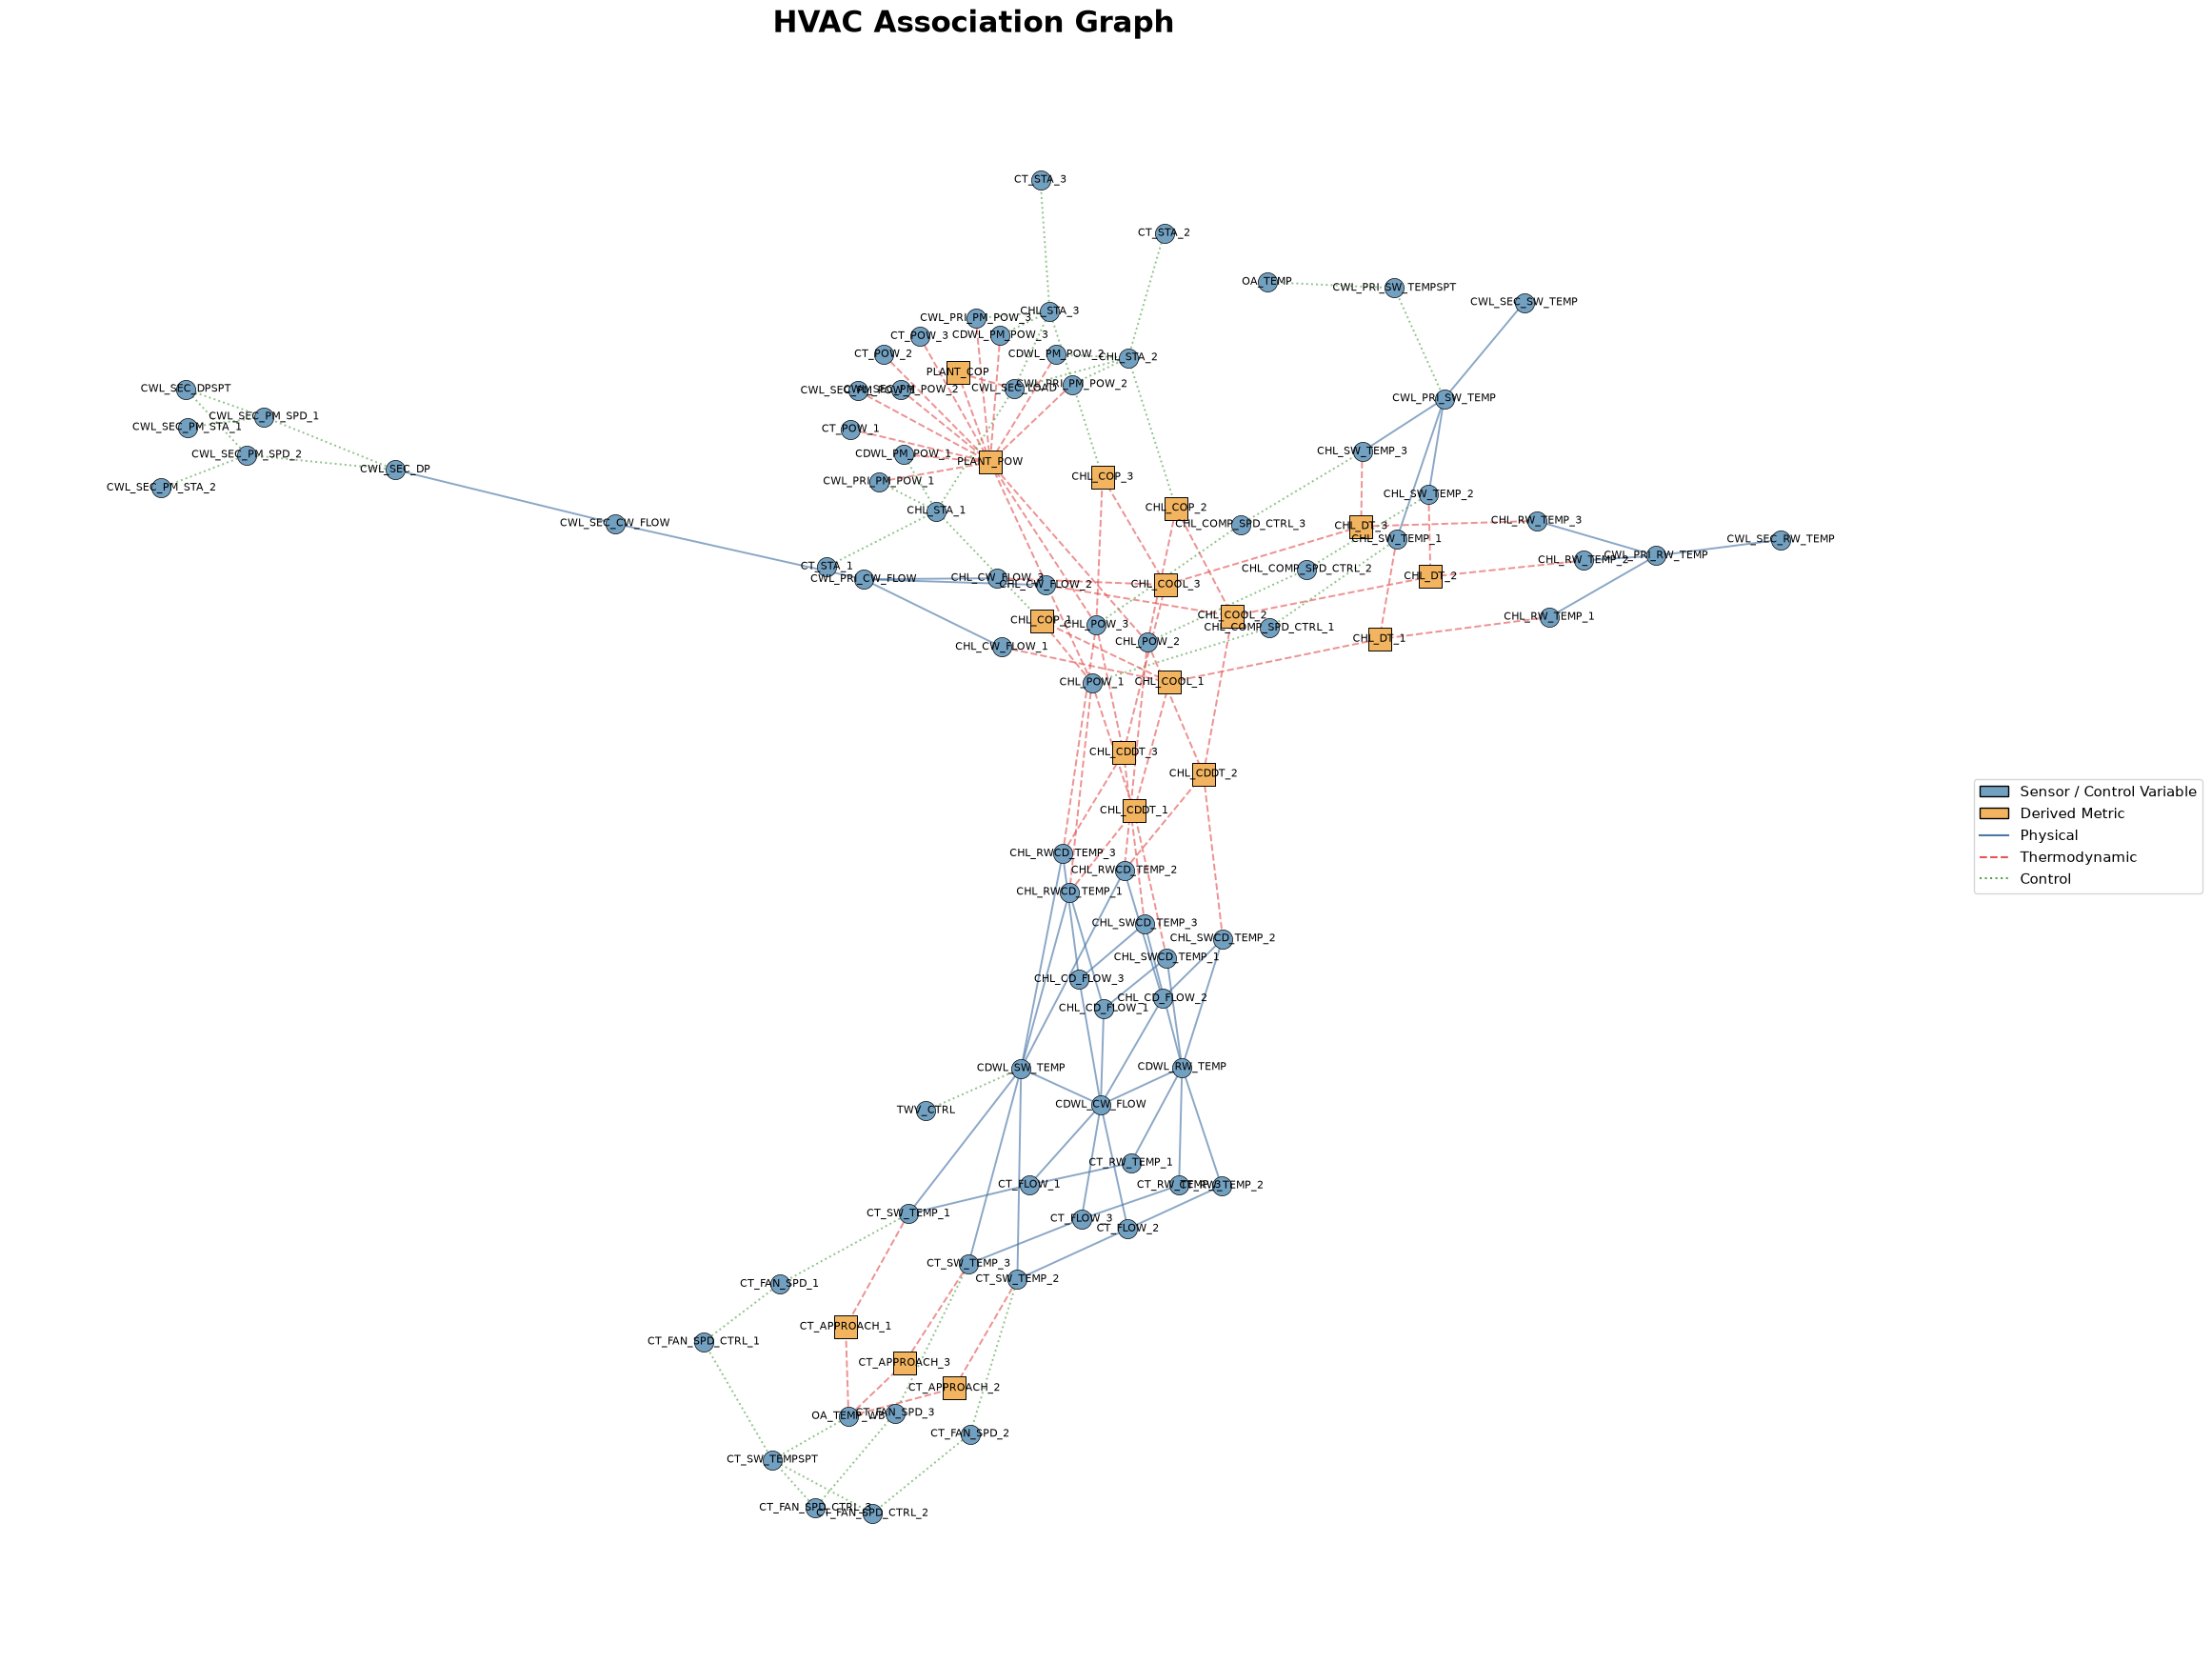

PNG saved to: C:\Users\Asus\Desktop\gc-arm-llm-hvac\notebooks\outputs\hvac_association_graph.png
SVG saved to: C:\Users\Asus\Desktop\gc-arm-llm-hvac\notebooks\outputs\hvac_association_graph.svg


In [42]:
# Draw the graph returned by src/graph.py.
layout_graph = nx.Graph()
layout_graph.add_nodes_from(G_built.nodes(data=True))
layout_graph.add_edges_from((source, target) for source, target in G_built.edges())

pos = nx.spring_layout(
    layout_graph,
    seed=42,
    k=1.25,
    iterations=500,
)

sensor_nodes = [
    node for node, data in G_built.nodes(data=True)
    if data["node_type"] == "sensor_or_control"
]
metric_nodes = [
    node for node, data in G_built.nodes(data=True)
    if data["node_type"] == "derived_metric"
]

edge_styles = {
    "physical": {"color": "#4C78A8", "style": "solid"},
    "thermodynamic": {"color": "#E45756", "style": "dashed"},
    "control": {"color": "#54A24B", "style": "dotted"},
}

fig, ax = plt.subplots(figsize=(30, 22))
fig.subplots_adjust(right=0.80)

for edge_type, style in edge_styles.items():
    edges = [
        (source, target)
        for source, target, data in G_built.edges(data=True)
        if data["edge_type"] == edge_type
    ]
    nx.draw_networkx_edges(
        layout_graph,
        pos,
        edgelist=edges,
        edge_color=style["color"],
        style=style["style"],
        width=1.4,
        alpha=0.65,
        ax=ax,
    )

nx.draw_networkx_nodes(
    layout_graph,
    pos,
    nodelist=sensor_nodes,
    node_color="#72A0C1",
    node_size=210,
    edgecolors="black",
    linewidths=0.5,
    ax=ax,
)

nx.draw_networkx_nodes(
    layout_graph,
    pos,
    nodelist=metric_nodes,
    node_color="#F2B45F",
    node_shape="s",
    node_size=300,
    edgecolors="black",
    linewidths=0.7,
    ax=ax,
)

nx.draw_networkx_labels(
    layout_graph,
    pos,
    font_size=8,
    font_weight="normal",
    ax=ax,
)

legend_items = [
    Patch(facecolor="#72A0C1", edgecolor="black", label="Sensor / Control Variable"),
    Patch(facecolor="#F2B45F", edgecolor="black", label="Derived Metric"),
    Line2D([0], [0], color="#4C78A8", linestyle="solid", label="Physical"),
    Line2D([0], [0], color="#E45756", linestyle="dashed", label="Thermodynamic"),
    Line2D([0], [0], color="#54A24B", linestyle="dotted", label="Control"),
]

fig.legend(
    handles=legend_items,
    loc="center left",
    bbox_to_anchor=(0.81, 0.5),
    fontsize=11,
    frameon=True,
)

ax.set_title("HVAC Association Graph", fontsize=22, fontweight="bold")
ax.axis("off")

OUTPUT_DIR = PROJECT_ROOT / "notebooks" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

png_path = OUTPUT_DIR / "hvac_association_graph.png"
svg_path = OUTPUT_DIR / "hvac_association_graph.svg"

fig.savefig(png_path, dpi=400, bbox_inches="tight")
fig.savefig(svg_path, bbox_inches="tight")

plt.show()

print("PNG saved to:", png_path)
print("SVG saved to:", svg_path)


In [43]:
# Verify that both graph exports were created.
for figure_path in (png_path, svg_path):
    print(
        figure_path.name,
        "| exists:", figure_path.is_file(),
        "| size (bytes):", figure_path.stat().st_size if figure_path.is_file() else 0,
    )
    assert figure_path.is_file() and figure_path.stat().st_size > 0


hvac_association_graph.png | exists: True | size (bytes): 2065750
hvac_association_graph.svg | exists: True | size (bytes): 177943


In [44]:
# Close the figure after saving both formats.
plt.close(fig)
print("Graph figure closed after export.")


Graph figure closed after export.


In [45]:
# Physical edge inventory (read-only view of src/graph.py's graph).
print("PHYSICAL EDGES IN THE CANONICAL GRAPH")
print("=" * 55)

for index, (source, target) in enumerate(physical_edges, start=1):
    print(f"{index:02}. {source}  <-->  {target}")


PHYSICAL EDGES IN THE CANONICAL GRAPH
01. CWL_PRI_CW_FLOW  <-->  CHL_CW_FLOW_1
02. CWL_PRI_CW_FLOW  <-->  CHL_CW_FLOW_2
03. CWL_PRI_CW_FLOW  <-->  CHL_CW_FLOW_3
04. CWL_PRI_CW_FLOW  <-->  CWL_SEC_CW_FLOW
05. CWL_PRI_SW_TEMP  <-->  CHL_SW_TEMP_1
06. CWL_PRI_SW_TEMP  <-->  CHL_SW_TEMP_2
07. CWL_PRI_SW_TEMP  <-->  CHL_SW_TEMP_3
08. CWL_PRI_SW_TEMP  <-->  CWL_SEC_SW_TEMP
09. CT_SW_TEMP_2  <-->  CDWL_SW_TEMP
10. CT_SW_TEMP_2  <-->  CT_FLOW_2
11. CT_SW_TEMP_1  <-->  CDWL_SW_TEMP
12. CT_SW_TEMP_1  <-->  CT_FLOW_1
13. CT_FLOW_2  <-->  CDWL_CW_FLOW
14. CT_FLOW_2  <-->  CT_RW_TEMP_2
15. CWL_SEC_DP  <-->  CWL_SEC_CW_FLOW
16. CHL_SWCD_TEMP_3  <-->  CDWL_RW_TEMP
17. CHL_SWCD_TEMP_3  <-->  CHL_CD_FLOW_3
18. CHL_RW_TEMP_1  <-->  CWL_PRI_RW_TEMP
19. CHL_RWCD_TEMP_3  <-->  CDWL_SW_TEMP
20. CHL_RWCD_TEMP_3  <-->  CHL_CD_FLOW_3
21. CHL_RW_TEMP_3  <-->  CWL_PRI_RW_TEMP
22. CWL_PRI_RW_TEMP  <-->  CHL_RW_TEMP_2
23. CWL_PRI_RW_TEMP  <-->  CWL_SEC_RW_TEMP
24. CT_RW_TEMP_1  <-->  CDWL_RW_TEMP
25. CT_RW_TEMP_1 

# 12. Reviewer-Requested Chiller Relationships


In [46]:
# Verify the additional per-chiller relationships requested in review.
required_typed_edges = []

for i in range(1, 4):
    required_typed_edges.extend([
        (f"CHL_RWCD_TEMP_{i}", f"CHL_POW_{i}", "thermodynamic"),
        (f"CHL_CDDT_{i}", f"CHL_COOL_{i}", "thermodynamic"),
        (f"CHL_CDDT_{i}", f"CHL_POW_{i}", "thermodynamic"),
        (f"CHL_SW_TEMP_{i}", f"CHL_COMP_SPD_CTRL_{i}", "control"),
        (f"CHL_COMP_SPD_CTRL_{i}", f"CHL_POW_{i}", "control"),
    ])

def has_typed_edge(graph, source, target, edge_type):
    return any(
        data.get("edge_type") == edge_type
        for data in graph.get_edge_data(source, target, default={}).values()
    )

missing_review_edges = [
    (source, target, edge_type)
    for source, target, edge_type in required_typed_edges
    if not has_typed_edge(G_built, source, target, edge_type)
]

print("Reviewer-requested relationships:", len(required_typed_edges))
print("Missing relationships:", missing_review_edges)

assert not missing_review_edges
print("Reviewer-requested chiller relationships: PASS")


Reviewer-requested relationships: 15
Missing relationships: []
Reviewer-requested chiller relationships: PASS


In [47]:
# 13. Final HVAC Association Graph Validation
node_type_counts = Counter(
    data["node_type"] for _, data in G_built.nodes(data=True)
)
edge_type_counts = Counter(
    data["edge_type"] for _, _, data in G_built.edges(data=True)
)
pair_counts = {
    k: len(graph_module.allowed_pairs(G_built, k))
    for k in [1, 2, 3]
}
component_count = nx.number_connected_components(G_built)
isolated_nodes = list(nx.isolates(G_built))

print("=" * 52)
print("FINAL HVAC ASSOCIATION GRAPH VALIDATION")
print("=" * 52)
print("Nodes:", G_built.number_of_nodes())
print("Edges:", G_built.number_of_edges())
print("Connected components:", component_count)
print("Isolated nodes:", isolated_nodes)
print("Configured graph.k:", GRAPH_K)

print("\nNode types:")
for node_type, count in sorted(node_type_counts.items()):
    print(f"  {node_type}: {count}")

print("\nEdge types:")
for edge_type, count in sorted(edge_type_counts.items()):
    print(f"  {edge_type}: {count}")

print("\nAllowed variable pairs:")
for k, count in pair_counts.items():
    print(f"  k={k}: {count}")

graph_validation_passed = (
    G_built.number_of_nodes() == 94
    and G_built.number_of_edges() == 140
    and node_type_counts == {"sensor_or_control": 77, "derived_metric": 17}
    and edge_type_counts == {"physical": 45, "thermodynamic": 55, "control": 40}
    and component_count == 1
    and not isolated_nodes
    and pair_counts == {1: 140, 2: 535, 3: 1163}
    and GRAPH_K == 2
)

print("\nGraph validation:", "PASS" if graph_validation_passed else "FAIL")
print(
    "Graph-constrained Apriori test:",
    "PASS" if final_apriori_test_passed else "FAIL",
)

assert graph_validation_passed
assert final_apriori_test_passed


FINAL HVAC ASSOCIATION GRAPH VALIDATION
Nodes: 94
Edges: 140
Connected components: 1
Isolated nodes: []
Configured graph.k: 2

Node types:
  derived_metric: 17
  sensor_or_control: 77

Edge types:
  control: 40
  physical: 45
  thermodynamic: 55

Allowed variable pairs:
  k=1: 140
  k=2: 535
  k=3: 1163

Graph validation: PASS
Graph-constrained Apriori test: PASS


## Conclusion

The notebook now uses the shared implementation in `src/graph.py` and the configured neighbourhood limit in `config.yaml`. It preserves the HVAC architecture and research context while avoiding duplicate graph definitions.

Final verified results:

- 94 nodes: 77 sensor/control variables and 17 derived metrics.
- 140 typed edges: 45 physical, 55 thermodynamic, and 40 control.
- One connected component and no isolated nodes.
- Allowed variable pairs: 140 (`k=1`), 535 (`k=2`), and 1,163 (`k=3`).
- Graph-constrained Apriori rejects a connected pair whose shortest-path distance is greater than the configured `k=2`.
- Graph exported in PNG and SVG formats.

The graph records derived-metric relationships; numerical calculation of the derived metrics remains part of preprocessing/feature engineering.
